In [2]:
import math
import os

import h5py
import plotly.graph_objects as go
import tensorflow as tf

2025-04-26 01:22:29.849356: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-26 01:22:29.950790: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-04-26 01:22:29.950821: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-26 01:22:29.959993: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-26 01:22:29.979124: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-26 01:22:29.979783: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [8]:
ber_results = {}

data_base_path = "../docker/output"
data = [
    #{
    #    "name": "M64-n48-N_tx25-N_rx01",
    #    "file": "BER-0-60km-17ps_5X_imdd-M64-n48-N_tx25-N_rx01.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx25-N_rx03",
    #    "file": "BER-0-60km-17ps_5X_imdd-M64-n48-N_tx25-N_rx03.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx25-N_rx05",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx05.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx25-N_rx07",
    #    "file": "BER-0-60km-17ps_5X_imdd-M64-n48-N_tx25-N_rx07.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx25-N_rx09",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx09.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx25-N_rx11",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx11.hd5",
    #},
    {
        "name": "M64-n48-N_tx25-N_rx15",
        "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx15.hd5",
    },
    {
        "name": "M64-n48-N_tx25-N_rx15-optimized_mapping",
        "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx15-optimized_mapping.hd5",
    },
    #{
    #    "name": "M64-n48-N_tx25-N_rx25",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx25.hd5",
    #},
    #{
    #    "name": "M64-n48-N_tx39-N_rx39",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx39-N_rx39.hd5",
    #}
]

for entry in data:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber_results[entry["name"]] = {
            "ber": list(f["ber"]),
            "length": list(f["channel__optical_fiber__length"])
        }

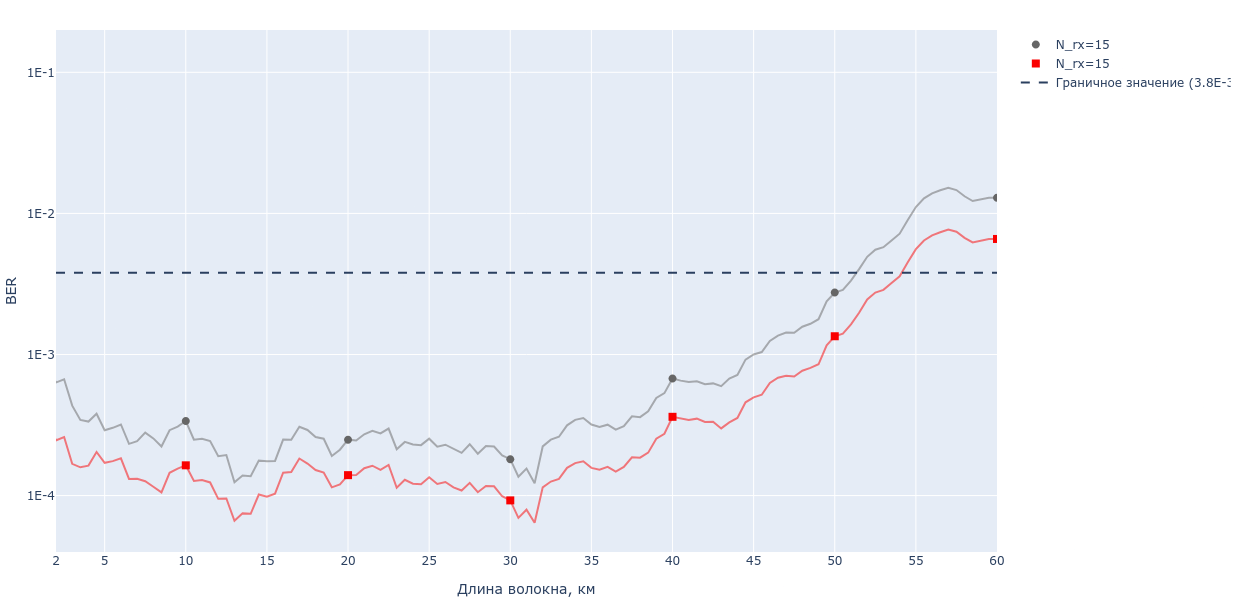

In [11]:
figure = go.Figure(layout=go.Layout(
    xaxis={
        "title": "Длина волокна, км",
        "tickmode": "array",
        "tickvals": [2.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0]
    },
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for color, marker, (name, ber_result) in zip(colors, markers, ber_results.items()):
    M, n, N_tx, N_rx = [int(i[-2:]) for i in name.split("-")[:4]]

    B = 336E9 * math.log2(M) / n

    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 6, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)
    
    #figure.add_trace(
    #    go.Scatter(
    #        x=ber_result["length"][::4],
    #        y=ber_result["ber"][::4],
    #        name=f"N_rx={N_rx}",
    #        mode="lines",
    #        marker=dict(size=8, symbol=marker),
    #        line={"color": color},
    #        opacity=1.0
    #    )
    #)
    
    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=f"N_rx={N_rx}",
            mode="lines",
            marker=dict(size=8, symbol=marker),
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure.add_trace(
        go.Scatter(
            x=ber_result["length"][::20],
            y=smoothed[::20],
            name=f"N_rx={N_rx}",
            mode="markers",
            marker=dict(size=8, symbol=marker),
            line={"color": color}
        )
    )

figure.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure.update_layout(
    autosize=True,
    height=600,
    width=900,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[2.0, 60.0],
    yaxis_range=[-4.4, -0.7]
)

figure.show()

In [8]:
figure.write_image("ber_by_distance_5X_cropped.svg")

In [27]:
ber_results_rx15 = {}

data_rx15 = [
    #{
    #    "name": "CD=17, α=0,2",
    #    "file": "BER-0-60km-17ps_imdd-M64-n48-N_tx25-N_rx15.hd5",
    #},
    {
        "name": "CD=4, α=0,2",
        "file": "BER-0-60km-04ps_imdd-M64-n48-N_tx25-N_rx15.hd5"
    }
]

for entry in data_rx15:
    with h5py.File(os.path.join(data_base_path, entry["file"])) as f:
        ber_results_rx15[entry["name"]] = {
            "ber": list(f["ber"]),
            "length": list(f["channel__optical_fiber__length"])
        }

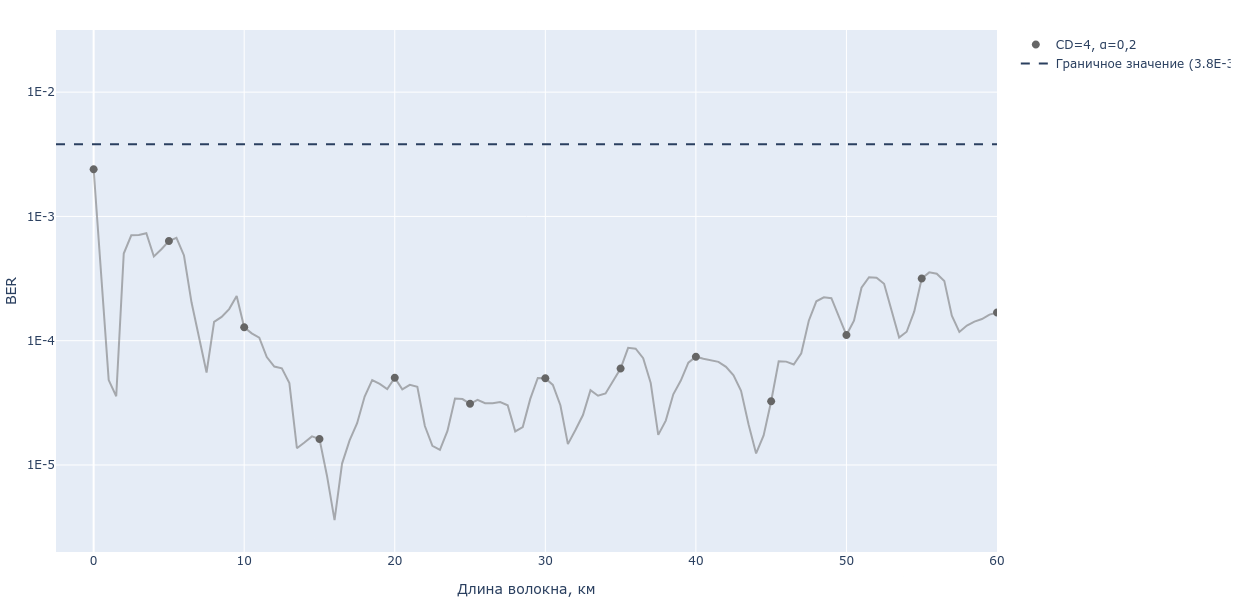

In [37]:
figure_rx15 = go.Figure(layout=go.Layout(
    xaxis={"title": "Длина волокна, км"},
    yaxis={
        "title": "BER",
        "type": "log",
        "tickmode": "array",
        "tickvals": [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0],
        "ticktext": ["1E-8", "1E-7", "1E-6", "1E-5", "1E-4", "1E-3", "1E-2", "1E-1", "1E0"]
    }
))

markers = ["circle", "square", "diamond", "cross", "x"]
colors = ["#666", "rgb(250, 0, 0)", "rgb(20, 180, 20)", "rgb(70, 70, 230)", "rgb(250, 100, 0)"]

for marker, color, (name, ber_result) in zip(markers, colors, ber_results_rx15.items()):
    smoothed = tf.math.reduce_mean(tf.signal.frame(ber_result["ber"], 4, 1, pad_end=True, pad_value=ber_result["ber"][-1]), axis=-1)

    figure_rx15.add_trace(
        go.Scatter(
            x=ber_result["length"][::1],
            y=smoothed[::1],
            name=name,
            mode="lines",
            marker=dict(size=8, symbol=marker),
            line={"color": color},
            opacity=0.5,
            showlegend=False
        )
    )

    figure_rx15.add_trace(
        go.Scatter(
            x=ber_result["length"][::10],
            y=smoothed[::10],
            name=name,
            mode="markers",
            marker=dict(size=8, symbol=marker),
            line={"color": color}
        )
    )

figure_rx15.add_hline(3.8e-3, line_dash="dash", name="Граничное значение (3.8E-3)", showlegend=True)
figure_rx15.update_layout(
    autosize=True,
    height=600,
    width=800,
    margin=dict(t=30, b=30, l=10, r=5),
    xaxis_range=[-2.5, 60.0],
    yaxis_range=[-5.7, -1.5]
)

figure_rx15.show()

In [48]:
figure_rx15.write_image("ber_by_distance_M64.svg")